# Lab 2

Convolutional neural nets with Keras framework  
By Alex Horyshevskyi  

### Installing dependencies

In [1]:
%pip install pandas[pyarrow] matplotlib seaborn keras tqdm scikit-learn albumentations --quiet
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130 --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### GPU check

In [2]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [3]:
import keras
import torch


print(f"Using Keras version: {keras.__version__}")
print(f"Using PyTorch version: {torch.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation will be performed on: {device}")

Using Keras version: 3.13.2
Using PyTorch version: 2.10.0+cu130
Computation will be performed on: cuda


### Inspecting the data

In [4]:
import pandas as pd


train_df = pd.read_csv("./train.csv", engine="pyarrow")
X_train = train_df.drop(columns=["label"])
y_train = train_df["label"]

print(train_df.shape)
train_df.head()

(42000, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
import pandas as pd


test = pd.read_csv("./test.csv", engine="pyarrow")
print(test.shape)
test.head()

(28000, 784)


,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
from torch.utils.data import Dataset
import albumentations as A
import numpy as np

class DigitDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray, augment=False):
        self.X = X
        self.y = y
        self.augment = augment
        self.transform = A.Compose([
            A.Rotate(limit=15, p=0.3),
            A.Affine(scale=(0.8, 1.2), p=0.3),
        ])

    def __getitem__(self, idx: int):
        x = self.X[idx]
        y = self.y[idx]

        if self.augment:
            augmented = self.transform(image=x)
            return augmented["image"], y

        return x, y

    def __len__(self):
        return len(self.X)

### Plot a few images from the dataset

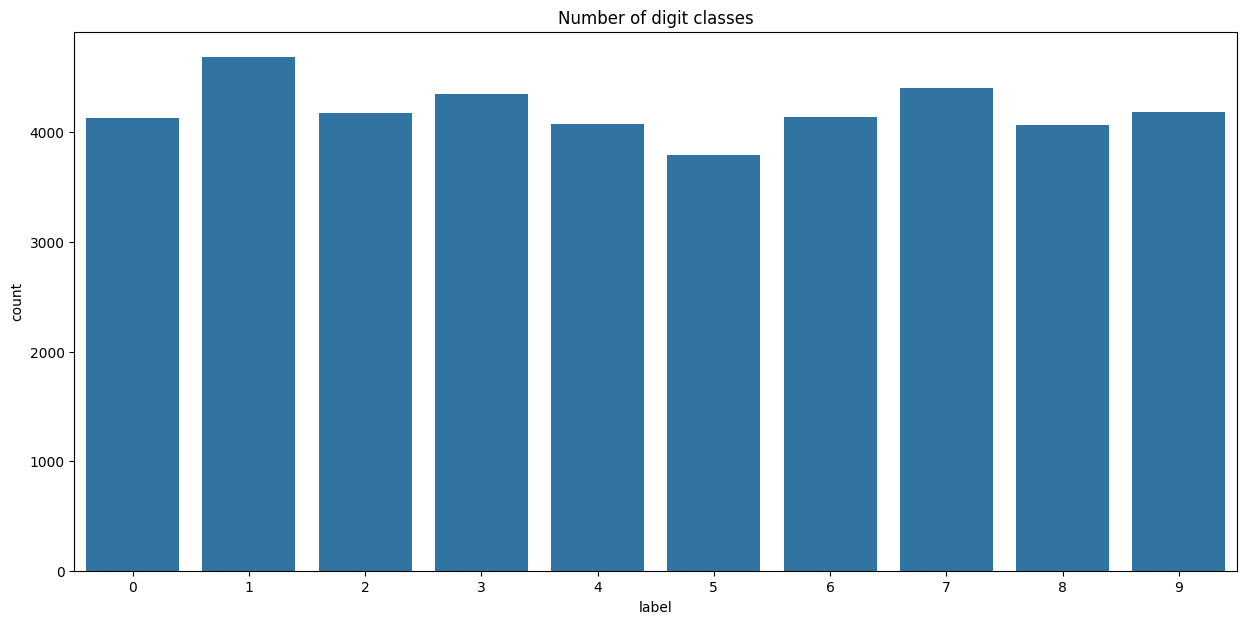

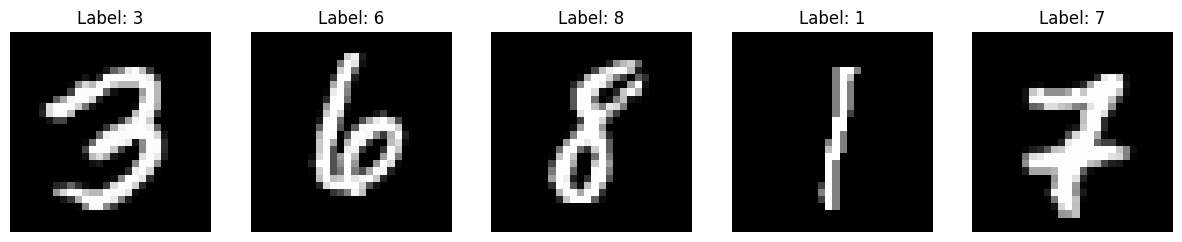

In [7]:
from datetime import datetime

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


def plot_classes():
    plt.figure(figsize=(15,7)) 
    sns.countplot(x=y_train)
    plt.title("Number of digit classes") 
    plt.show()


def plot_image(images: list[tuple[pd.Series, str]]):
    count = len(images)
    plt.figure(figsize=(count * 3, 3))

    for idx, (image, label) in enumerate(images):
        image = np.asarray(image).reshape(28, 28)
        plt.subplot(1, count, idx + 1)
        plt.imshow(image, cmap="gray")
        plt.title(f"Label: {label}")
        plt.axis("off")
    
    plt.show()


plot_classes()

random_seed = int(datetime.now().timestamp())
generator = np.random.default_rng(random_seed)
plot_image([
    (X_train.loc[idx], y_train.loc[idx])
    for idx in generator.choice(X_train.index, size=5)
])

### Construct a CNN for MNIST dataset

In [8]:
from keras import Sequential
from keras.layers import (
    BatchNormalization,
    Layer,
    Input,
    Conv2D,
    MaxPool2D,
    Dropout,
    Flatten,
    Dense,
    ReLU,
    Rescaling,
)
from dataclasses import dataclass, field


@dataclass
class ConvBlockConfig:
    filters: int
    kernel_size: tuple[int, int]
    pool_size: tuple[int, int] | None = (2, 2)  # None = skip pooling
    dropout: float = 0.25


@dataclass
class ModelConfig:
    blocks: list[ConvBlockConfig] = field(default_factory=lambda: [
        ConvBlockConfig(8, (5, 5)),
        ConvBlockConfig(16, (3, 3)),
    ])
    dense_units: int = 256
    dense_dropout: float = 0.3
    optimizer: str = "adam"
    loss: str = "sparse_categorical_crossentropy"
    metrics: list[str] = field(default_factory=lambda: ["accuracy"])


def convolve_block(cfg: ConvBlockConfig) -> list[Layer]:
    layers = [
        Conv2D(
            filters=cfg.filters,
            kernel_size=cfg.kernel_size,
            padding="same",
        ),
        BatchNormalization(),
        ReLU(),
    ]
    if cfg.pool_size is not None:
        layers.append(MaxPool2D(pool_size=cfg.pool_size))
    if cfg.dropout > 0:
        layers.append(Dropout(cfg.dropout))
    return layers


def construct_model(cfg: ModelConfig) -> Sequential:
    convolve_layers = [
        layer
        for block in cfg.blocks
        for layer in convolve_block(block)
    ]

    model = Sequential(
        [
            Input(shape=(28, 28, 1)),
            # Normalization
            Rescaling(1.0 / 255),
            *convolve_layers,
            # Fully connected layer
            Flatten(),
            Dense(cfg.dense_units, activation="relu"),
            Dropout(cfg.dense_dropout),
            Dense(10, activation="softmax"),
        ]
    )

    model.compile(
        optimizer=cfg.optimizer,
        loss=cfg.loss,
        metrics=cfg.metrics,
    )
    return model


def construct_lenet5() -> Sequential:
    """https://medium.com/@siddheshb008/lenet-5-architecture-explained-3b559cb2d52b"""
    model = Sequential(
        [
            # Standard LeNet-5 architecture has (32, 32, 1) input, but our images are (28, 28, 1)
            Input(shape=(28, 28, 1)),
            # Normalization
            Rescaling(1.0 / 255),
            # Convolutional layers
            Conv2D(6, (5, 5), activation="tanh"),
            MaxPool2D((2, 2)),
            Conv2D(16, (5, 5), activation="tanh"),
            MaxPool2D((2, 2)),
            # Fully connected layers
            Flatten(),
            Dense(120, activation="tanh"),
            Dense(84, activation="tanh"),
            Dense(10, activation="softmax"),
        ]
    )

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

### Training the model

In [9]:
from keras.callbacks import Callback, EarlyStopping, History, ReduceLROnPlateau
from keras.models import Sequential
import numpy as np
from torch.utils.data import DataLoader


def train_model(
        model: Sequential, 
        loader: DataLoader,
        val_data: tuple[np.ndarray, np.ndarray],
        epochs: int = 10, 
        batch_size: int = 64,
        callbacks: list[Callback] | None = None
    ) -> History:
    if callbacks is None:
        callbacks = [
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
            EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        ]
    history = model.fit(
        loader,
        validation_data=val_data,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
    )
    return history

### Evaluating the model

In [10]:
from keras.callbacks import History
from keras.models import Sequential
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpecFromSubplotSpec
from sklearn.model_selection import train_test_split


def evaluate_model(model: Sequential, X_train: np.ndarray, y_train: np.ndarray):
    loss, accuracy = model.evaluate(X_train, y_train)
    return loss, accuracy


def plot_model(
    history: History,
    predictions: np.ndarray | None = None,
    X_test_images: np.ndarray | None = None,
):
    _, ax = (
        plt.subplots(2, 2, figsize=(15, 10))
        if predictions is not None
        else plt.subplots(1, 2, figsize=(15, 5), squeeze=False)
    )

    # Plot training & validation accuracy values
    ax[0, 0].plot(history.history["accuracy"])
    ax[0, 0].plot(history.history["val_accuracy"])
    ax[0, 0].set_title("Model accuracy")
    ax[0, 0].set_ylabel("Accuracy")
    ax[0, 0].set_xlabel("Epoch")
    ax[0, 0].legend(["Train", "Validation"], loc="upper left")

    # Plot training & validation loss values
    ax[0, 1].plot(history.history["loss"])
    ax[0, 1].plot(history.history["val_loss"])
    ax[0, 1].set_title("Model loss")
    ax[0, 1].set_ylabel("Loss")
    ax[0, 1].set_xlabel("Epoch")
    ax[0, 1].legend(["Train", "Validation"], loc="upper left")

    if predictions is not None:
        ax[1, 0].hist(predictions, bins=np.arange(-0.5, 10.5, 1), rwidth=0.8)
        ax[1, 0].set_title("Predicted class distribution")
        ax[1, 0].set_xlabel("Class")
        ax[1, 0].set_ylabel("Frequency")

        ax[1, 1].axis("off")

        # Plot a few sample predictions from test images when available.
        if X_test_images is not None and len(X_test_images) == len(predictions):
            sample_size = min(5, len(predictions))
            generator = np.random.default_rng(int(datetime.now().timestamp()))
            sample_indices = generator.choice(
                len(predictions), size=sample_size, replace=False
            )
            sample_images = X_test_images[sample_indices]
            sample_labels = predictions[sample_indices]

            gs = GridSpecFromSubplotSpec(
                1, sample_size, subplot_spec=ax[1, 1].get_subplotspec()
            )
            for idx, (image, label) in enumerate(zip(sample_images, sample_labels)):
                sub_ax = plt.subplot(gs[idx])
                sub_ax.imshow(image.reshape(28, 28), cmap="gray")
                sub_ax.set_title(f"Predicted: {label}")
                sub_ax.axis("off")

    plt.tight_layout()
    plt.show()


def test_model(model: Sequential, X_test: np.ndarray) -> np.ndarray:
    predictions = model.predict(X_test)
    predicted_classes = np.argmax(predictions, axis=1)
    return predicted_classes


def run_model(
    model: Sequential | None = None,
    optimizer: str = "adam",
    blocks: list[ConvBlockConfig] | None = None,
    loss: str = "sparse_categorical_crossentropy",
    metrics: list[str] | None = None,
    epochs: int = 10,
    batch_size: int = 1024,
):
    print(
        f"Running model with optimizer={optimizer}, loss={loss}, metrics={metrics}, epochs={epochs}, batch_size={batch_size}"
    )

    X_train_reshaped = X_train.to_numpy().reshape(-1, 28, 28, 1).astype("float32")
    y_train_reshaped = y_train.to_numpy().astype("int64")
    X_test_reshaped = test.to_numpy().reshape(-1, 28, 28, 1).astype("float32")

    val_size = int(0.2 * len(X_train_reshaped))
    X_train_f, X_val, y_train_f, y_val = train_test_split(
        X_train_reshaped, y_train_reshaped, test_size=val_size, random_state=42
    )

    dataset = DigitDataset(X_train_f, y_train_f, augment=True)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=8, pin_memory=True)

    if model is None:
        model_config = ModelConfig(
            blocks=blocks
            or [
                ConvBlockConfig(filters=8, kernel_size=(5, 5)),
                ConvBlockConfig(filters=16, kernel_size=(3, 3)),
            ],
            optimizer=optimizer,
            loss=loss,
            metrics=metrics or ["accuracy"],
        )

        model = construct_model(model_config)

    history = train_model(model, loader, (X_val, y_val), epochs, batch_size)

    loss, accuracy = evaluate_model(model, X_train_reshaped, y_train_reshaped)
    print(f"Final Loss: {loss:.4f}, Final Accuracy: {accuracy:.4f}")

    predictions = test_model(model, X_test_reshaped)
    plot_model(history, predictions, X_test_reshaped)

### Run the pipeline

Running model with optimizer=adam, loss=sparse_categorical_crossentropy, metrics=None, epochs=10, batch_size=1024
Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.5410 - loss: 1.4087 - val_accuracy: 0.8370 - val_loss: 1.6204 - learning_rate: 0.0010
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.7964 - loss: 0.6213 - val_accuracy: 0.7604 - val_loss: 1.3942 - learning_rate: 0.0010
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8490 - loss: 0.4601 - val_accuracy: 0.7593 - val_loss: 1.1693 - learning_rate: 0.0010
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.8718 - loss: 0.3931 - val_accuracy: 0.8001 - val_loss: 0.9815 - learning_rate: 0.0010
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.8907 - loss: 0.3376 - val_accuracy: 0.8938 - val_loss: 0.6975 - learning_rate: 0.0010
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9036 - loss: 0.2947 - val_accuracy: 0.9211 - val_loss: 0.5164 - le

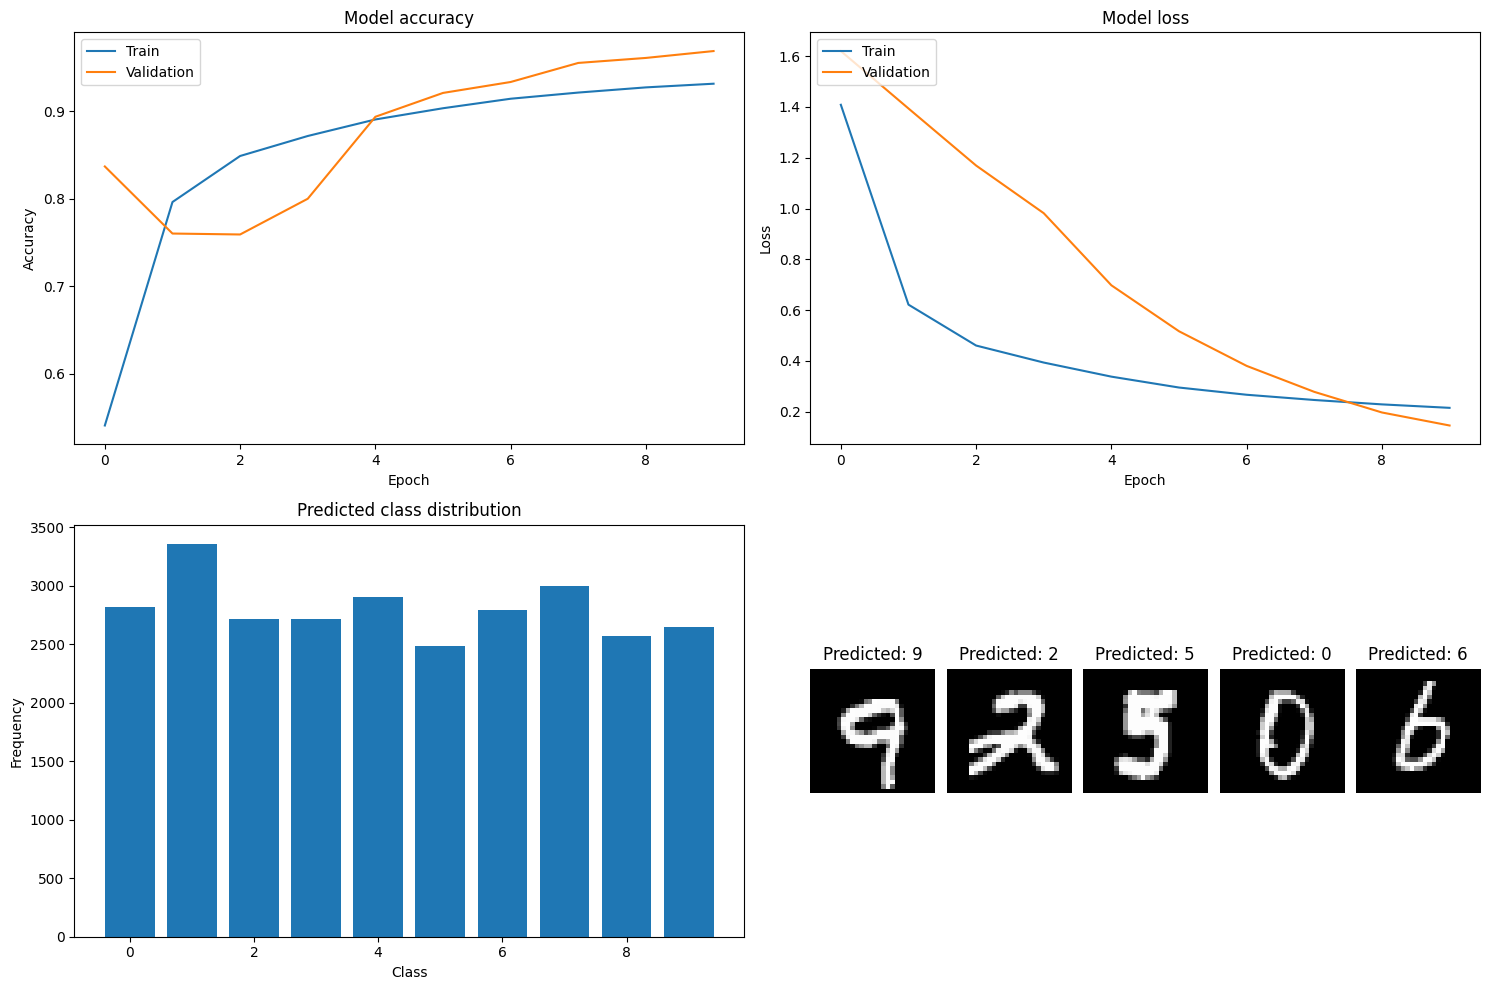

Running model with optimizer=sgd, loss=sparse_categorical_crossentropy, metrics=None, epochs=10, batch_size=1024
Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.2247 - loss: 2.3744 - val_accuracy: 0.4399 - val_loss: 2.1618 - learning_rate: 0.0100
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.4336 - loss: 1.6622 - val_accuracy: 0.6251 - val_loss: 1.9822 - learning_rate: 0.0100
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.5577 - loss: 1.3291 - val_accuracy: 0.7120 - val_loss: 1.7721 - learning_rate: 0.0100
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.6260 - loss: 1.1331 - val_accuracy: 0.7817 - val_loss: 1.5518 - learning_rate: 0.0100
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.6737 - loss: 0.9916 - val_accuracy: 0.8279 - val_loss: 1.3223 - learning_rate: 0.0100
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7029 - loss: 0.9089 - val_accuracy: 0.8548 - val_loss: 1.1048 - lea

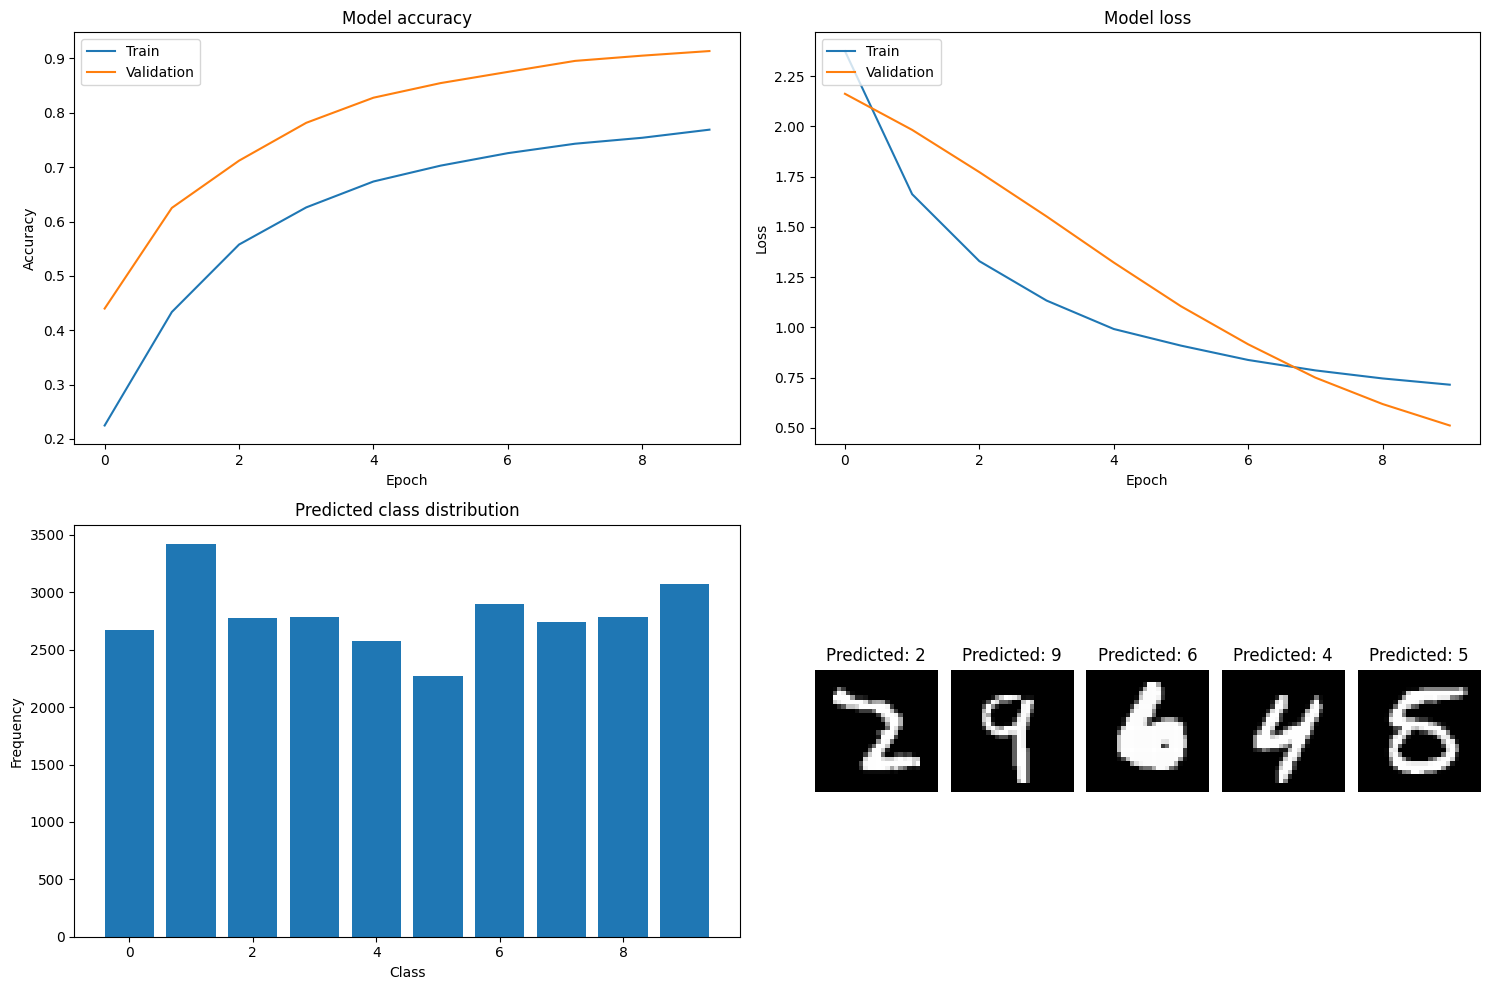

Running model with optimizer=adam, loss=sparse_categorical_crossentropy, metrics=None, epochs=10, batch_size=1024
Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.5859 - loss: 1.3096 - val_accuracy: 0.1267 - val_loss: 2.0546 - learning_rate: 0.0010
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - accuracy: 0.8630 - loss: 0.4410 - val_accuracy: 0.1083 - val_loss: 2.5002 - learning_rate: 0.0010
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.9057 - loss: 0.3001 - val_accuracy: 0.1108 - val_loss: 2.6778 - learning_rate: 0.0010
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - accuracy: 0.9253 - loss: 0.2403 - val_accuracy: 0.1181 - val_loss: 2.5094 - learning_rate: 5.0000e-04
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - accuracy: 0.9318 - loss: 0.2185 - val_accuracy: 0.2252 - val_loss: 1.9849 - learning_rate: 5.0000e-04
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.9393 - loss: 0.1934 - val_accuracy: 0.4740 - val_loss: 1.3

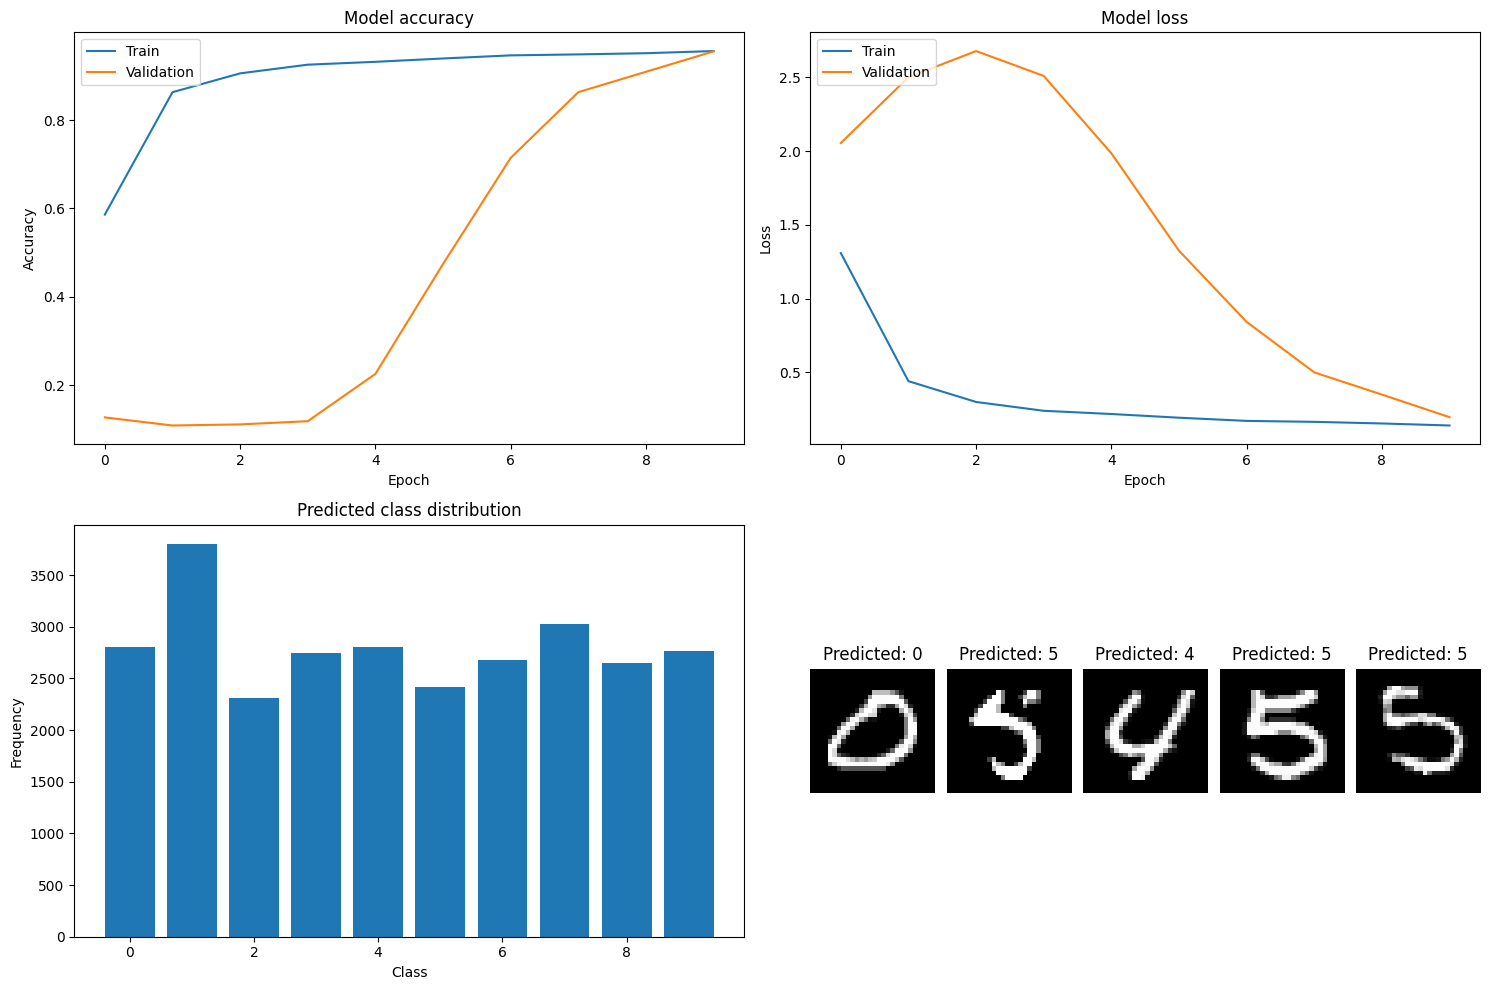

Running model with optimizer=adam, loss=sparse_categorical_crossentropy, metrics=None, epochs=10, batch_size=1024
Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.6452 - loss: 1.3012 - val_accuracy: 0.8474 - val_loss: 0.5364 - learning_rate: 0.0010
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8435 - loss: 0.5241 - val_accuracy: 0.9040 - val_loss: 0.3364 - learning_rate: 0.0010
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8841 - loss: 0.3807 - val_accuracy: 0.9292 - val_loss: 0.2552 - learning_rate: 0.0010
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9066 - loss: 0.3040 - val_accuracy: 0.9415 - val_loss: 0.2021 - learning_rate: 0.0010
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9233 - loss: 0.2542 - val_accuracy: 0.9515 - val_loss: 0.1721 - learning_rate: 0.0010
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9325 - loss: 0.2200 - val_accuracy: 0.9582 - val_loss: 0.1453 - le

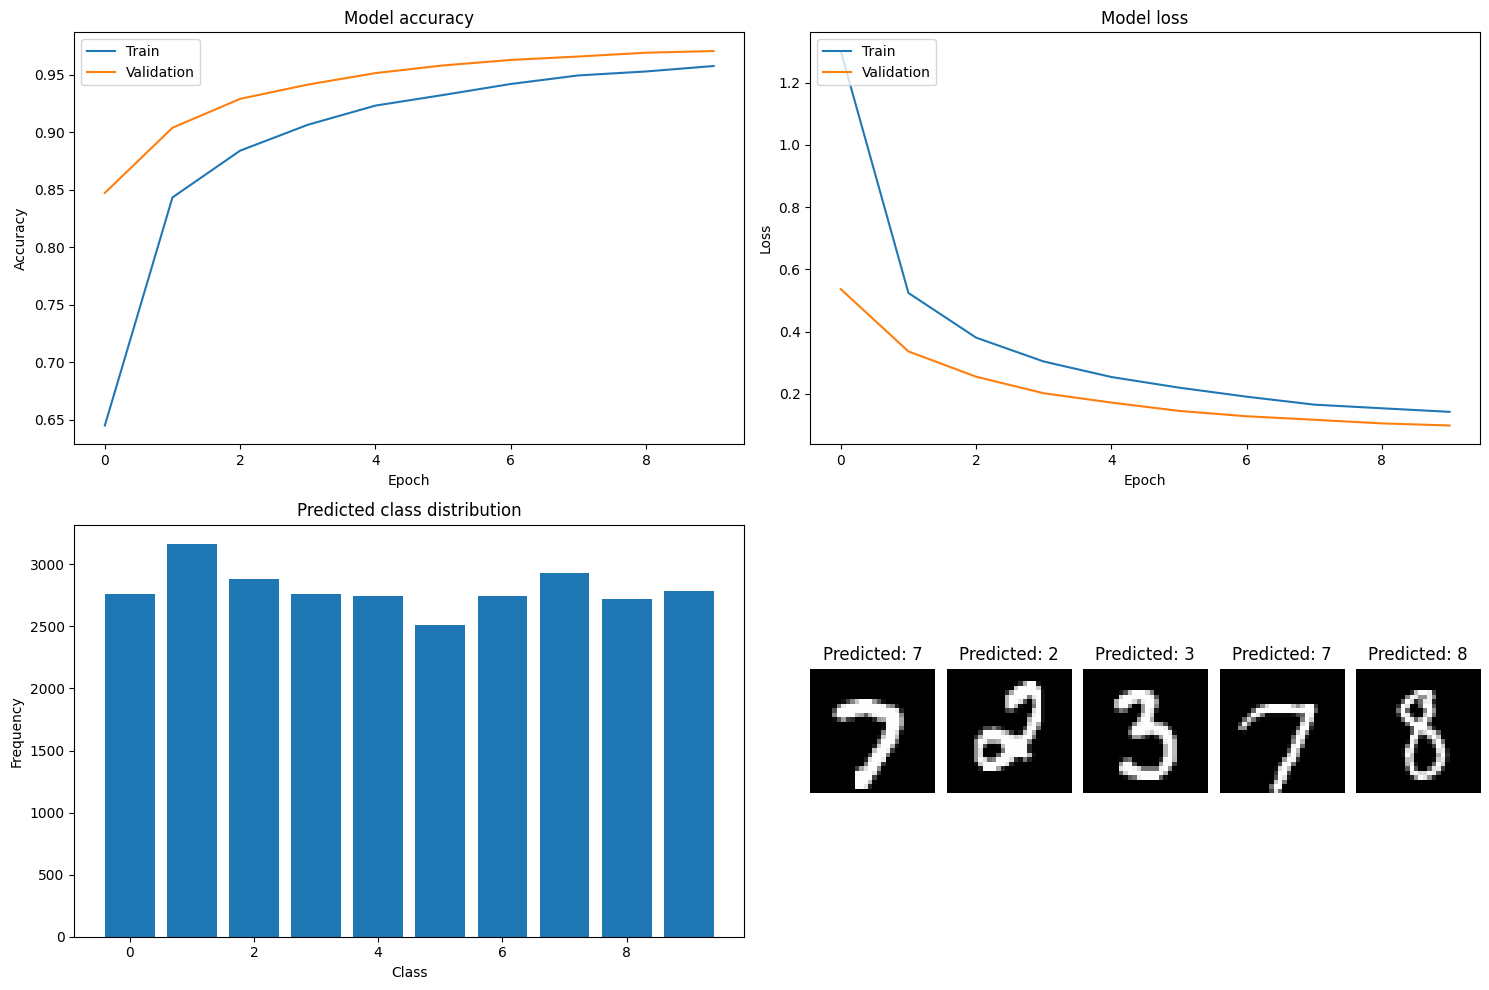

In [11]:
run_model()

run_model(optimizer="sgd")

run_model(
    blocks=[
        ConvBlockConfig(filters=32, kernel_size=(5, 4)),
        ConvBlockConfig(filters=32, kernel_size=(5, 4)),
        ConvBlockConfig(filters=64, kernel_size=(3, 2), pool_size=None),
        ConvBlockConfig(filters=64, kernel_size=(3, 2), pool_size=None),
    ]
)

run_model(model=construct_lenet5())